ORIGINAL DATASET:
   Study_Hours  Attendance  Assignment_Score  Internal_Marks
0            2          50                40              35
1            4          60                50              45
2            6          70                60              55
3            8          80                75              70
4           10          90                90              88
5            3          55                45              40
6            7          75                70              65
7            9          85                85              82

NORMALIZED DATASET:
   Study_Hours  Attendance  Assignment_Score  Internal_Marks
0         0.00        0.00               0.0            0.00
1         0.25        0.25               0.2            0.19
2         0.50        0.50               0.4            0.38
3         0.75        0.75               0.7            0.66
4         1.00        1.00               1.0            1.00
5         0.12        0.12               0.1  

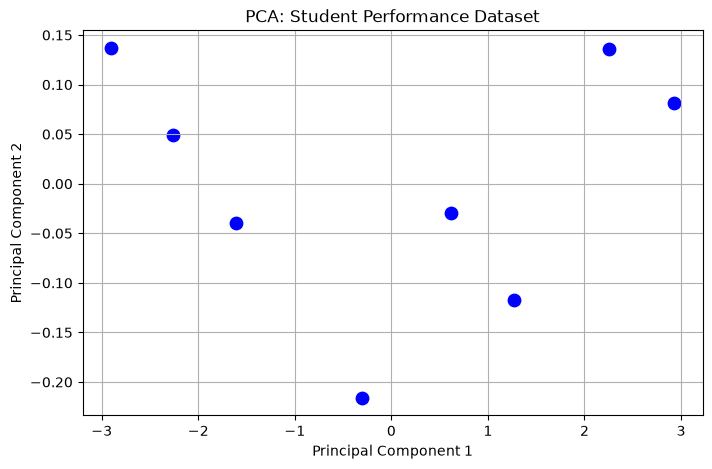

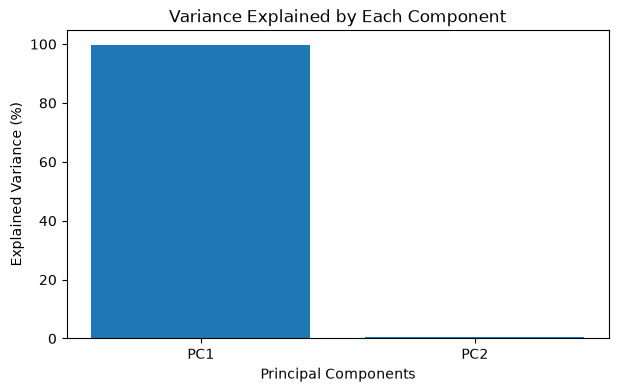


All three result files have been saved.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA


data = {
    'Study_Hours': [2, 4, 6, 8, 10, 3, 7, 9],
    'Attendance': [50, 60, 70, 80, 90, 55, 75, 85],
    'Assignment_Score': [40, 50, 60, 75, 90, 45, 70, 85],
    'Internal_Marks': [35, 45, 55, 70, 88, 40, 65, 82]
}

df = pd.DataFrame(data)

print("ORIGINAL DATASET:")
print(df)


normalizer = MinMaxScaler()

normalized_data = normalizer.fit_transform(df)

normalized_df = pd.DataFrame(
    normalized_data,
    columns=df.columns
)

print("\nNORMALIZED DATASET:")
print(normalized_df.round(2))


scaler = StandardScaler()

standardized_data = scaler.fit_transform(df)

standardized_df = pd.DataFrame(
    standardized_data,
    columns=df.columns
)

print("\nSTANDARDIZED DATASET:")
print(standardized_df.round(2))

print("\nMean of standardized features:")
print(standardized_df.mean().round(2))

print("\nStandard deviation of standardized features:")
print(standardized_df.std(ddof=0).round(2))

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

pca = PCA(n_components=2)

pca_data = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    pca_data,
    columns=[
        'Principal_Component_1',
        'Principal_Component_2'
    ]
)

print("\nPCA TRANSFORMED DATASET:")
print(pca_df.round(2))


# Step 6: Display explained variance
print("\nEXPLAINED VARIANCE RATIO:")
print(pca.explained_variance_ratio_.round(4))

print("\nTOTAL VARIANCE RETAINED:")
print(round(pca.explained_variance_ratio_.sum() * 100, 2), "%")


plt.figure(figsize=(8, 5))

plt.scatter(
    pca_df['Principal_Component_1'],
    pca_df['Principal_Component_2'],
    color='blue',
    s=80
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA: Student Performance Dataset')

plt.grid(True)
plt.show()


plt.figure(figsize=(7, 4))

components = ['PC1', 'PC2']

plt.bar(
    components,
    pca.explained_variance_ratio_ * 100
)

plt.xlabel('Principal Components')
plt.ylabel('Explained Variance (%)')
plt.title('Variance Explained by Each Component')

plt.show()


normalized_df.to_csv('normalized_data.csv', index=False)
standardized_df.to_csv('standardized_data.csv', index=False)
pca_df.to_csv('pca_results.csv', index=False)

print("\nAll three result files have been saved.")